# 03 — LoRA fine-tuning: validated plan and real experiment reports

**Objective.** Train a small PEFT LoRA adapter for SmolLM2-360M-Instruct, using only the train split and the validation split for feedback. The held-out test set is reserved for later comparison. All training logic lives in `train_lora.py` and `src/tinydevassist/training.py`.

**Status:** training has **not** run in this notebook. The default path is an offline dry run that verifies source/split hashes and prints a bounded experiment plan. Set `RUN_TRAINING=True` only after measuring the base model on the same pinned revision and installing `pip install -e '.[train,notebooks]'`. A 36-example authored seed is insufficient for generalization claims.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

root = Path.cwd()
if not (root / "pyproject.toml").is_file():
    root = root.parent
assert (root / "pyproject.toml").is_file(), "Open this notebook from notebooks/ or the repo root"
env = os.environ.copy()
env["PYTHONPATH"] = str(root / "src") + os.pathsep + env.get("PYTHONPATH", "")
report_path = root / "outputs/train_lora.json"
print("TinyDevAssist repository detected; experiment artifacts are ignored by Git.")

TinyDevAssist repository detected; experiment artifacts are ignored by Git.


## 1. Verify the seed dataset and preview the training plan

This regenerates deterministic, ignored splits and verifies their hashes. A dry run **does not import Transformers, download weights, or train**. It prints estimated optimizer steps, not observed runtime metrics.

In [2]:
subprocess.run(
    [sys.executable, str(root / "prepare_data.py"), "--seed", "42"],
    cwd=root,
    env=env,
    capture_output=True,
    text=True,
    check=True,
)
result = subprocess.run(
    [sys.executable, str(root / "train_lora.py")],
    cwd=root,
    env=env,
    capture_output=True,
    text=True,
    check=True,
)
plan = json.loads(result.stdout)
assert plan["status"] == "dry_run_only" and not plan["training_executed"]
print("Dataset counts:", plan["split_counts"])
print("Planned optimizer steps (not executed):", plan["estimated_optimizer_steps"])
print("Pinned model revision required:", plan["requires_pinned_revision"])
print("Measured baseline required:", plan["requires_measured_baseline"])

Dataset counts: {'train': 24, 'validation': 6, 'test': 6}
Planned optimizer steps (not executed): 6
Pinned model revision required: True
Measured baseline required: True


## 2. Visualize the verified split sizes

The chart uses the manifest-derived counts, **not model performance measurements**.

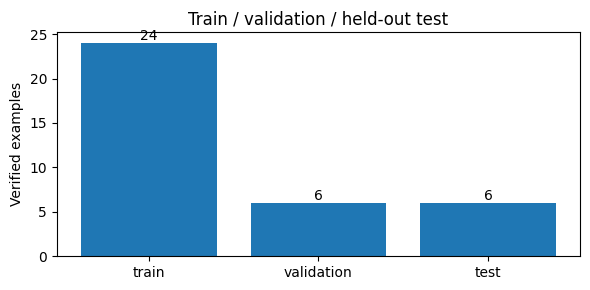

In [3]:
try:
    import matplotlib.pyplot as plt

    labels = list(plan["split_counts"])
    values = [plan["split_counts"][name] for name in labels]
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(labels, values)
    ax.set_ylabel("Verified examples")
    ax.set_title("Train / validation / held-out test")
    for i, value in enumerate(values):
        ax.text(i, value, str(value), ha="center", va="bottom")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib unavailable; split counts are shown above.")

## 3. Execute only with explicit consent and a pinned model revision

First run `python inference.py --revision <40-char-SHA>` with the same model and all six test prompts. Then set `RUN_TRAINING=True` and replace `PINNED_REVISION`. The training CLI checks the baseline report, all input hashes, and non-overwriting output paths before importing heavy ML libraries. The default does nothing beyond the dry run.

In [4]:
RUN_TRAINING = False
PINNED_REVISION = ""  # Supply the upstream 40-character model commit SHA.
if RUN_TRAINING:
    assert len(PINNED_REVISION) == 40, "Pin the model revision before training"
    subprocess.run(
        [sys.executable, str(root / "train_lora.py"), "--revision", PINNED_REVISION, "--execute"],
        cwd=root,
        env=env,
        check=True,
    )
else:
    print("Skipped real training: set RUN_TRAINING=True after a measured baseline.")

Skipped real training: set RUN_TRAINING=True after a measured baseline.


## 4. Inspect actual results only when a completed report exists

The report is generated **only after successful training and adapter saving**. Never substitute mock loss curves or placeholder quality metrics.

In [5]:
if report_path.is_file():
    report = json.loads(report_path.read_text(encoding="utf-8"))
    assert report["status"] == "trained", "Report does not represent a completed run"
    assert report["source_sha256"] == plan["dataset_source_sha256"], "Dataset changed"
    print("Model revision:", report["requested_revision"])
    print("Trainable parameters:", report["trainable_parameters"])
    print("Train metrics:", report["train_metrics"])
    print("Validation metrics:", report["validation_metrics"])
else:
    print("No completed training report. No loss or model-quality claims are available.")

No completed training report. No loss or model-quality claims are available.


## Interpretation and next steps

- A successful **dry run** proves config parsing, source/split provenance, and bounded planning only.
- Real training requires installed Transformers/PEFT, model weights, a measured baseline, and a pinned upstream SHA. Adapter loading and compatibility still require integration tests.
- Evaluate the adapted model on held-out test prompts in notebook 04, and add independently reviewed questions before claiming meaningful improvement.
- Do not commit checkpoints, credentials, private data, or fabricated experiment results.